# Acme Sports: trend analysis (100 weeks)

Five analyses required by the specification, run on all **100 weekly MRP runs** (Aug 2025 to Jun 2027)

In [26]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from engine.data_loader import load_data

plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False})
d = load_data()
pr = d.prs.merge(d.runs[["run_id", "week_number"]], on="run_id")
so, fu, cust = d.sales_orders, d.utilization.copy(), d.customers.set_index("customer_id")
art = d.articles.set_index("article_id")
print(f"{len(pr):,} requisitions · {pr['requested_qty'].sum():,.0f} units · {len(so):,} sales orders · "
      f"{pr['week_number'].nunique()} weeks")

25,141 requisitions · 17,554,643 units · 17,845 sales orders · 100 weeks


## 1. Seasonal demand curve

### 1.1 Weekly demand and sales-order value

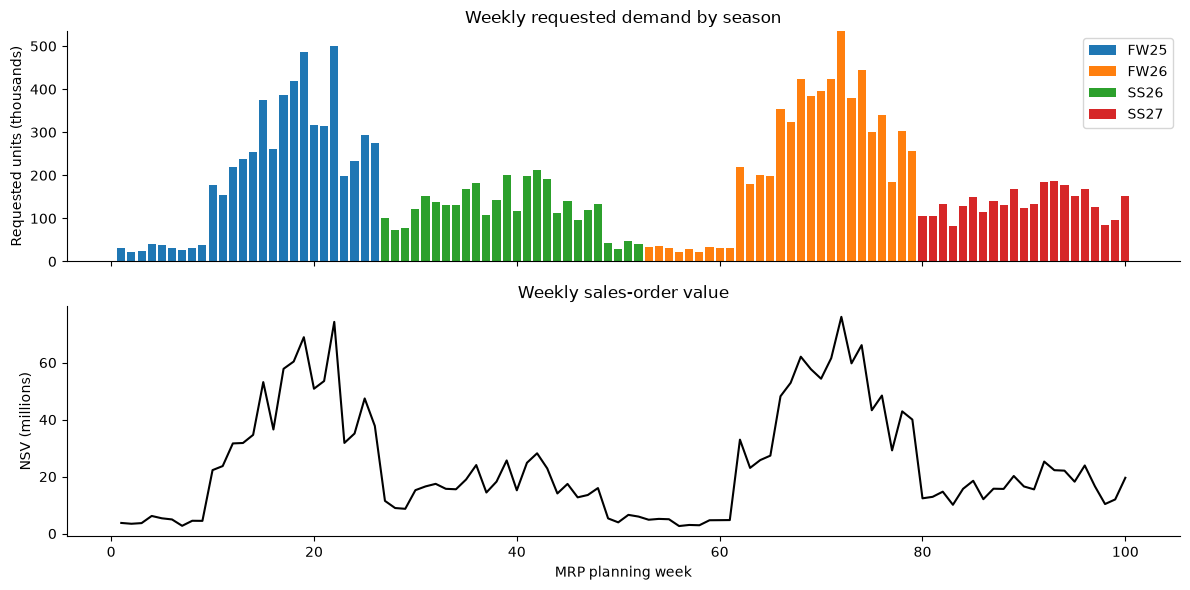

Highest-demand weeks:
week_number
72    534298
22    499844
19    486701


In [27]:
# Requested units by week and season
weekly = (
    pr.groupby(["week_number", "season"])["requested_qty"]
    .sum()
    .unstack(fill_value=0)
)

# Sales-order value linked to each PR's planning week
weekly_nsv = (
    so.merge(
        pr[["pr_id", "week_number"]],
        on="pr_id",
        validate="many_to_one"
    )
    .groupby("week_number")["net_sales_value"]
    .sum()
)

colors = {
    "FW25": "tab:blue",
    "FW26": "tab:orange",
    "SS26": "tab:green",
    "SS27": "tab:red"
}

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

bottom = np.zeros(len(weekly))
for season in weekly.columns:
    units = weekly[season] / 1_000
    axes[0].bar(
        weekly.index, units, bottom=bottom,
        color=colors[season], label=season
    )
    bottom += units.to_numpy()

axes[0].set_ylabel("Requested units (thousands)")
axes[0].set_title("Weekly requested demand by season")
axes[0].legend()

axes[1].plot(
    weekly_nsv.index, weekly_nsv / 1_000_000,
    color="black"
)
axes[1].set_ylabel("NSV (millions)")
axes[1].set_xlabel("MRP planning week")
axes[1].set_title("Weekly sales-order value")

plt.tight_layout()
plt.show()

print("Highest-demand weeks:")
print(weekly.sum(axis=1).nlargest(3).to_string())

Fall/Winter has higher demand peaks than Spring/Summer, while the periods between seasons show lower demand. The largest peak is week 72, with 534298 requested units. Sales-order value broadly follows the demand peaks, although it covers only order-backed demand. These peaks indicate when to examine factory capacity and possible pull-forward into earlier buying windows. Factory-level checks are needed before recommending a move.

| Finding | Buy Plan rule | What the engine should do |
|---|---|---|
| FW demand has sharp peaks | Capacity-driven pull-forward | Check future factory loads. If overloaded, evaluate moving eligible demand into earlier buying windows with spare capacity. |
| Demand is lower between seasons | Factory capacity and certification | Check whether certified factories have available capacity in these earlier periods. Low demand alone does not prove spare capacity. |
| Requests appear in different planning weeks | Rule 1: release timing | Calculate purchase timing from each PR’s delivery date and manufacturing/transit lead times. Do not purchase everything immediately. |

### 1.2 Peak-to-trough ratio by market

In [28]:
# Weekly requested units for each market
market_weekly = (
    pr.groupby(["week_number", "market_destination"])["requested_qty"]
    .sum()
    .unstack(fill_value=0)
    .sort_index()
)

# Smooth demand using four complete weeks
rolling = market_weekly.rolling(window=4, min_periods=4).mean()

ratio = (
    rolling.max() / rolling.min()
).sort_values(ascending=False)

print("Peak-to-trough ratio (four-week average):")
print(ratio.round(1).to_string())

Peak-to-trough ratio (four-week average):
market_destination
AR    22.1
CO    21.6
US    21.0
BR    19.8
MX    19.6
PE    18.9
CL    13.7


Peak demand is approximately 13–22 times trough demand across the seven markets. Argentina and Comlumbia show the largest relative swings. This supports checking capacity before high-demand periods and MOQ/MPQ compliance during quieter periods. The ratios measure demand variation, not market size; minimum quantities must still be checked for individual article–market groups.

| Finding | Buy Plan rule | What the engine should do |
|---|---|---|
| Market demand varies by approximately 13–22× | Rule 3: MOQ/MPQ | Check minimum quantities for actual article–market lots, especially during quieter periods. |
| Some lots may be too small | Rule 2: consolidation | Combine eligible requests for the same article and market within the permitted 15-day delivery-date span. |
| A lot may narrowly miss its minimum | Rule 4: piggybacking | Check the 5% shortfall condition before automatically bringing eligible future demand forward. |

## 2. Factory utilisation and backup trigger frequency

### 2.1 Which factories reach the threshold most often?

            weeks_observed  weeks_at_or_above_85  weeks_above_100
factory_id                                                       
ACME-BD02              100                    29               21
ACME-CN04              100                    80               78
ACME-ID03              100                    77               77
ACME-IN06              100                    26               22
ACME-TR05              100                    49               41
ACME-VN01              100                    79               78


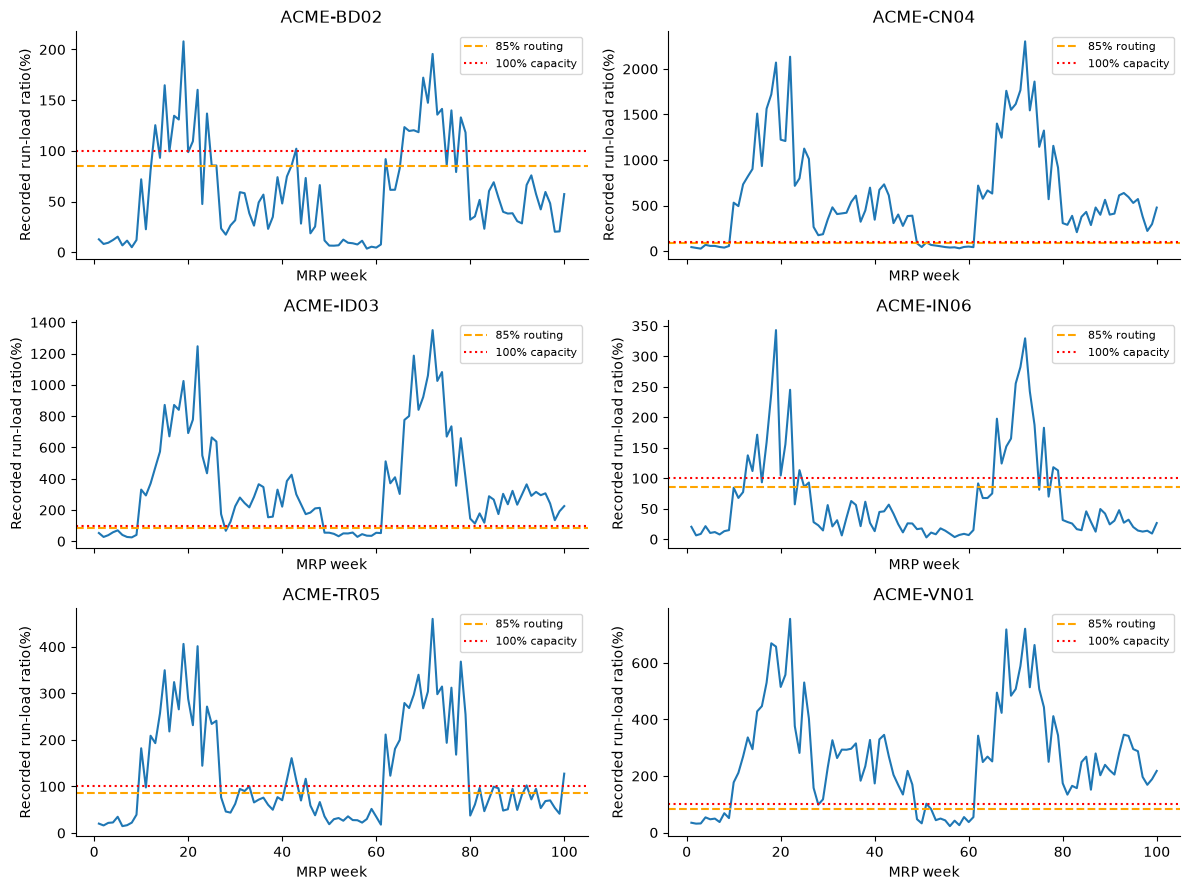

In [39]:
f = fu.copy()

f["at_85"] = f["utilization_pct"] >= 85
f["above_100"] = f["utilization_pct"] > 100

summary = f.groupby("factory_id").agg(
    weeks_observed=("run_id", "nunique"),
    weeks_at_or_above_85=("at_85", "sum"),
    weeks_above_100=("above_100", "sum")
)

print(summary.to_string())

# Separate charts make individual factories easier to inspect.
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)

for ax, (factory, data) in zip(
    axes.flat, f.groupby("factory_id")
):
    data = data.sort_values("week_number")

    ax.plot(data["week_number"], data["utilization_pct"])
    ax.axhline(85, color="orange", linestyle="--", label="85% routing")
    ax.axhline(100, color="red", linestyle=":", label="100% capacity")
    ax.set_title(factory)
    ax.set_ylabel("Recorded run-load ratio(%)")
    ax.set_xlabel("MRP week")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

CN04, VN01 and ID03 reach the recorded 85% threshold most often. These figures describe the baseline generator's run-level demand pressure. They do not establish the final quantity produced by each factory in those weeks.

### 2.2 In which seasons?

In [30]:
season_percent = (
    f.groupby(["factory_id", "season"])["at_85"]
    .mean()
    .unstack()
    * 100
)

print("Percentage of weeks reaching 85%:")
print(season_percent.round(1).to_string())

print("\nObserved weeks per season:")
print(f.groupby("season")["run_id"].nunique().to_string())

Percentage of weeks reaching 85%:
season      FW25  FW26  SS26   SS27
factory_id                         
ACME-BD02   50.0  51.9   7.7    0.0
ACME-CN04   65.4  66.7  92.3  100.0
ACME-ID03   65.4  66.7  80.8  100.0
ACME-IN06   50.0  48.1   0.0    0.0
ACME-TR05   65.4  66.7  26.9   33.3
ACME-VN01   65.4  66.7  88.5  100.0

Observed weeks per season:
season
FW25    26
FW26    27
SS26    26
SS27    21


CN04, ID03 and VN01 reach the routing threshold in every observed SS27 week. IN06 remains below the threshold throughout SS26 and SS27. BD02 reaches it in 7.7% of SS26 weeks and none of the SS27 weeks. Recorded run-level demand pressure therefore differs by factory and does not simply follow overall demand. SS27 contains 21 observed weeks, compared with 26–27 for the other seasons.

### 2.3 Is backup routing associated with utilization?

In [31]:
backup = (
    pr.groupby(["run_id", "primary_factory"])
    .agg(
        pr_count=("pr_id", "size"),
        backup_count=("backup_triggered", "sum")
    )
    .reset_index()
    .merge(
        f[["run_id", "factory_id", "utilization_pct", "at_85"]],
        left_on=["run_id", "primary_factory"],
        right_on=["run_id", "factory_id"],
        how="left",
        validate="one_to_one"
    )
)

assert backup["utilization_pct"].notna().all(), "Missing factory matches"

backup["backup_rate"] = backup["backup_count"] / backup["pr_count"]

rates = backup.groupby("at_85")[["pr_count", "backup_count"]].sum()
rates["backup_percent"] = (
    100 * rates["backup_count"] / rates["pr_count"]
)

print("Backup routing by primary-factory threshold status:")
print(rates.round(1).to_string())

correlation = backup["backup_rate"].corr(backup["utilization_pct"])
print(f"\nFactory-run correlation: {correlation:.2f}")

Backup routing by primary-factory threshold status:
       pr_count  backup_count  backup_percent
at_85                                        
False      4656             0             0.0
True      20485         14086            68.8

Factory-run correlation: 0.76


Backup routing is recorded for 68.8% of PRs associated with primary factories at or above 85%, compared with none below the threshold. The factory-run correlation is 0.76, showing a strong positive association in the supplied data. This is an association within the supplied synthetic data. It does not prove that backup routing reduced overload or that the engine's capacity calculations are correct.

| Finding | Relevant rule | Planning implication |
|---|---|---|
| Some factories frequently reach 85% | Backup routing | Check projected primary load and certified backup availability before assigning additional demand. |
| Some factories have fewer threshold breaches | Factory certification | Investigate available capacity, but do not assume every article can use those factories. |
| Recorded loads often exceed 100% | Capacity-driven pull-forward | Investigate earlier production opportunities after confirming what the utilization data represents. |

## 3. Pull-forward opportunity map

### 3.1 Show busy and quiet fatory-weeks

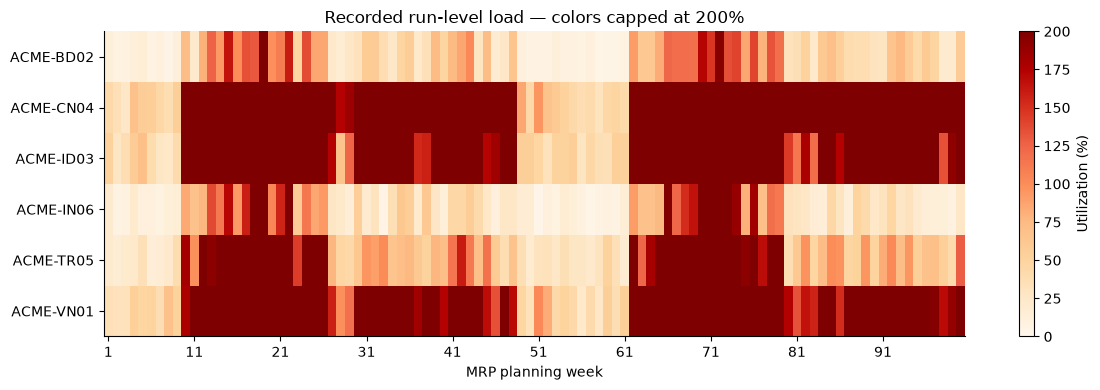

In [40]:
capacity = fu.pivot(
    index="factory_id",
    columns="week_number",
    values="utilization_pct"
).sort_index(axis=1)

fig, ax = plt.subplots(figsize=(12, 4))

image = ax.imshow(
    capacity,
    aspect="auto",
    cmap="OrRd",
    vmin=0,
    vmax=200
)

positions = list(range(0, len(capacity.columns), 10))
ax.set_xticks(positions)
ax.set_xticklabels(capacity.columns[positions])
ax.set_yticks(range(len(capacity.index)))
ax.set_yticklabels(capacity.index)

ax.set_xlabel("MRP planning week")
ax.set_title("Recorded run-level load — colors capped at 200%")
fig.colorbar(image, ax=ax, label="Utilization (%)")

plt.tight_layout()
plt.show()

The heatmap shows higher and lower recorded demand pressure across factories and planning runs. Earlier low-load runs identify candidates for historical investigation. They do not, by themselves, prove that physical production capacity was available.

### 3.2 Estimate capacity without counting it twice

In [49]:
SOURCE_THRESHOLD = 85
QUIET_THRESHOLD = 60
DESTINATION_LIMIT = 100  # Client-confirmed normal capacity ceiling

rows = []

for factory, data in fu.sort_values("week_number").groupby("factory_id"):

    quiet = data[data["utilization_pct"] < QUIET_THRESHOLD]

    # Available capacity shared by all proposed moves.
    remaining = {
        int(r.week_number): max(
            0,
            DESTINATION_LIMIT / 100 * float(r.weekly_capacity) - float(r.units_consumed)
        )
        for r in quiet.itertuples()
    }

    busy = data[data["utilization_pct"] >= SOURCE_THRESHOLD]

    for r in busy.itertuples():
        earlier = quiet[quiet["week_number"] < r.week_number]

        if earlier.empty:
            target_week, quantity = None, 0
        else:
            target_week = int(earlier.iloc[-1]["week_number"])

            excess = max(
                0,
                r.units_consumed
                - SOURCE_THRESHOLD / 100 * r.weekly_capacity
            )

            quantity = min(excess, remaining[target_week])
            remaining[target_week] -= quantity

        rows.append({
            "factory": factory,
            "busy_week": r.week_number,
            "earlier_week": target_week,
            "capacity_estimate": quantity
        })

opportunities = pd.DataFrame(rows)

summary = opportunities.groupby("factory").agg(
    busy_weeks=("busy_week", "size"),
    with_earlier_week=("earlier_week", "count"),
    estimated_units=("capacity_estimate", "sum")
)

print(summary.round(0).to_string())
print(
    "\nHistorical load-shifting estimate:",
    f"{opportunities['capacity_estimate'].sum():,.0f} units"
)

           busy_weeks  with_earlier_week  estimated_units
factory                                                  
ACME-BD02          29                 29          60003.0
ACME-CN04          80                 80          22500.0
ACME-ID03          77                 77          12803.0
ACME-IN06          26                 26          41432.0
ACME-TR05          49                 49          51029.0
ACME-VN01          79                 79          20036.0

Historical load-shifting estimate: 207,803 units


Using the supplied run-level loads, this screening method estimates 207,803 units of possible load redistribution with a 100% destination ceiling. Destination headroom is reserved only once. This is not a confirmed movable PR volume: routing records may count demand at multiple factories, and the calculation does not yet select eligible PRs or validate production timing and MOQ/MPQ after movement.

### 3.3 Identify potential MOQ problems

In [42]:
requests = pr.merge(
    fu[["run_id", "factory_id", "utilization_pct"]],
    left_on=["run_id", "assigned_factory"],
    right_on=["run_id", "factory_id"],
    validate="many_to_one"
)

groups = (
    requests[requests["utilization_pct"] >= SOURCE_THRESHOLD]
    .groupby(["run_id", "factory_id", "article_id", "market_destination"])
    ["requested_qty"]
    .sum()
    .reset_index(name="units")
)

groups["below_moq"] = groups["units"] < 300

moq_summary = groups.groupby("market_destination").agg(
    groups_checked=("units", "size"),
    groups_below_moq=("below_moq", "sum")
)

moq_summary["below_moq_percent"] = (
    100 * moq_summary["groups_below_moq"]
    / moq_summary["groups_checked"]
)

print(moq_summary.round(1).to_string())

                    groups_checked  groups_below_moq  below_moq_percent
market_destination                                                     
AR                            1635               342               20.9
BR                            2150               389               18.1
CL                            1627               358               22.0
CO                            1761               382               21.7
MX                            2083               401               19.3
PE                            1402               319               22.8
US                            1800               396               22.0


Of the 12,458 run–factory–article–market groups assigned to factories with recorded load ratios at or above 85%, 2,587 contain fewer than 300 units, or approximately 20.8%. This is a quantity screening result, not the MOQ/MPQ impact of actual pull-forward moves. Monthly buying-window and 15-day RDD grouping rules have not yet been applied.

| Finding | Business rule | Required check |
|---|---|---|
| Earlier quiet weeks exist | Capacity-driven pull-forward | Select eligible demand and reserve destination capacity once. |
| Some demand groups are small | MOQ/MPQ | Recalculate minimum quantities after each proposed move. |
| Demand is brought forward | Release timing and consolidation | Check earlier visibility, lead times and permitted delivery-date grouping. |

## Analysis 4 — Forecast vs. firm coverage

### 4.1 Weekly order cover rates

               total_prs  order_backed  forecast_only  coverage_pct
range_version                                                      
V1                  3608          1686           1922          46.7
V2                  6726          3426           3300          50.9
V3                  4790          2716           2074          56.7

Overall coverage: 51.8%


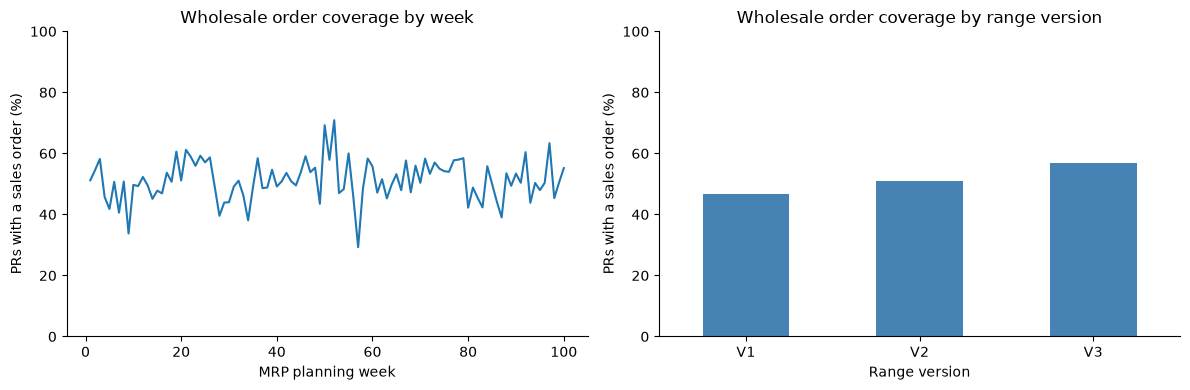

In [43]:
# Select wholesale PRs.
ws = pr[
    pr["channel_id"].astype(str).str.zfill(2) == "01"
].copy()

ws["covered"] = ws["pr_id"].isin(so["pr_id"])

# Coverage by planning week.
weekly_coverage = ws.groupby("week_number")["covered"].mean() * 100

# Coverage by range version.
coverage = ws.groupby("range_version").agg(
    total_prs=("pr_id", "size"),
    order_backed=("covered", "sum")
).reindex(["V1", "V2", "V3"])

coverage["forecast_only"] = coverage["total_prs"] - coverage["order_backed"]
coverage["coverage_pct"] = (
    100 * coverage["order_backed"] / coverage["total_prs"]
)

print(coverage.round(1).to_string())
print(f"\nOverall coverage: {ws['covered'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

weekly_coverage.plot(ax=axes[0])
axes[0].set(
    title="Wholesale order coverage by week",
    xlabel="MRP planning week",
    ylabel="PRs with a sales order (%)",
    ylim=(0, 100)
)

coverage["coverage_pct"].plot(
    kind="bar", ax=axes[1], color="steelblue", rot=0
)
axes[1].set(
    title="Wholesale order coverage by range version",
    xlabel="Range version",
    ylabel="PRs with a sales order (%)",
    ylim=(0, 100)
)

plt.tight_layout()
plt.show()

Overall, 51.8% of wholesale PRs have a matching sales order. Coverage increases from 46.7% in V1 to 56.7% in V3. These percentages compare groups of PRs; they do not track the same requests becoming confirmed over time.

### 4.2 Estimated value of forecast-only wholesale demand based on season

Estimated value of forecast-only wholesale demand ($ millions):
season
FW25    299.8
SS26    169.7
FW26    350.7
SS27    154.8


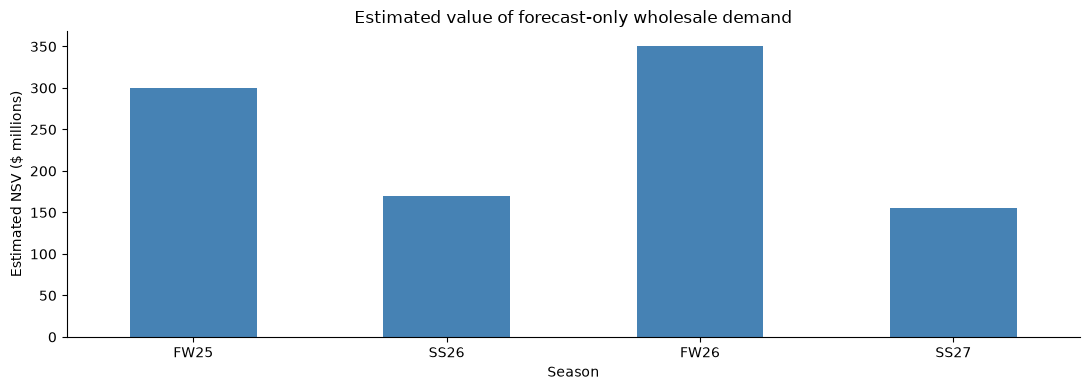

In [44]:
# Total sales-order value associated with each PR.
nsv_by_pr = (
    so.groupby("pr_id")["net_sales_value"]
    .sum()
    .rename("order_nsv")
)

valued_ws = ws.merge(
    nsv_by_pr, on="pr_id", how="left", validate="one_to_one"
)

# Estimate value per unit using order-backed wholesale PRs.
firm = valued_ws[valued_ws["covered"]].groupby("article_id").agg(
    nsv=("order_nsv", "sum"),
    units=("requested_qty", "sum")
)

value_per_unit = firm["nsv"] / firm["units"]

forecast = valued_ws[~valued_ws["covered"]].copy()
forecast["estimated_nsv"] = (
    forecast["requested_qty"]
    * forecast["article_id"].map(value_per_unit)
)

assert forecast["estimated_nsv"].notna().all(), "Missing article value estimate"

season_value = (
    forecast.groupby("season")["estimated_nsv"].sum() / 1_000_000
).reindex(["FW25", "SS26", "FW26", "SS27"])

print("Estimated value of forecast-only wholesale demand ($ millions):")
print(season_value.round(1).to_string())

ax = season_value.plot(kind="bar", color="steelblue", rot=0)
ax.set(
    title="Estimated value of forecast-only wholesale demand",
    xlabel="Season",
    ylabel="Estimated NSV ($ millions)"
)
plt.tight_layout()
plt.show()

Forecast-only wholesale demand has an estimated value of $299.8M in FW25, $169.7M in SS26, $350.7M in FW26 and $154.8M in SS27. Estimates use each article's average sales value per requested unit from order-backed wholesale PRs. These amounts represent potential value, not confirmed revenue or realized losses.

| Finding | Buy Plan rule | Planning implication |
|---|---|---|
| About half of wholesale PRs have no sales order | Rule 5: wholesale order confirmation | Defer unconfirmed wholesale demand unless an applicable exception allows purchase. |
| Forecast-only demand carries estimated potential value | Exception review | Show estimated value when reviewing exceptions. Send conflicting rules to the planner rather than automatically committing the purchase. |

## 5 Analysis 5 — NSV by market and credit rating

### 5.1 By credit and quarter

               nsv_million  share_pct
credit_rating                        
A                   1937.5       79.8
B                    425.1       17.5
C                     66.5        2.7


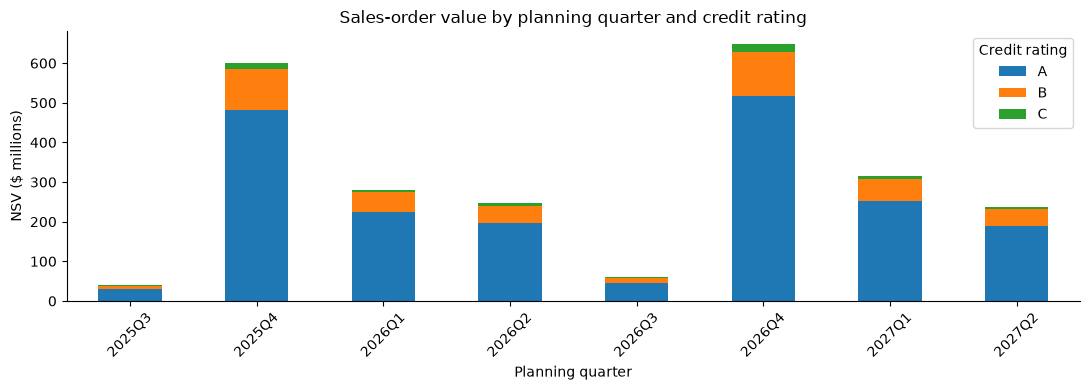

In [45]:
# Use PR destination market, not the customer's home market.
y = (
    so.drop(columns=["market_destination"], errors="ignore")
    .merge(
        d.customers[["customer_id", "credit_rating"]],
        on="customer_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        pr[["pr_id", "market_destination", "mrp_run_date"]],
        on="pr_id",
        how="left",
        validate="many_to_one"
    )
)

assert y["credit_rating"].notna().all(), "Missing customer credit rating"
assert y["mrp_run_date"].notna().all(), "Missing PR planning date"

y["planning_quarter"] = (
    pd.to_datetime(y["mrp_run_date"]).dt.to_period("Q").astype(str)
)

# Full aggregation required by the specification.
quarterly_exposure = (
    y.groupby(["planning_quarter", "market_destination", "credit_rating"])
    ["net_sales_value"]
    .sum()
    .reset_index(name="nsv")
)

rating_summary = (
    y.groupby("credit_rating")["net_sales_value"]
    .sum()
    .to_frame("nsv")
)

rating_summary["nsv_million"] = rating_summary["nsv"] / 1_000_000
rating_summary["share_pct"] = (
    100 * rating_summary["nsv"] / rating_summary["nsv"].sum()
)

print(rating_summary[["nsv_million", "share_pct"]].round(1).to_string())

quarter_chart = (
    quarterly_exposure.groupby(["planning_quarter", "credit_rating"])["nsv"]
    .sum().unstack(fill_value=0) / 1_000_000
)

ax = quarter_chart.plot(
    kind="bar", stacked=True, figsize=(11, 4), rot=45
)
ax.set(
    title="Sales-order value by planning quarter and credit rating",
    xlabel="Planning quarter",
    ylabel="NSV ($ millions)"
)
ax.legend(title="Credit rating")
plt.tight_layout()
plt.show()

A-rated customers account for 79.8% of recorded sales-order value, B-rated customers for 17.5%, and C-rated customers for 2.7%. C-rated customers have approximately $66.5M in order value. These figures describe exposure by credit rating, not expected financial losses.

Quarters are based on the associated PR's planning date because the sales-order table has no actual order-date field. They represent planning-period exposure, not recognized quarterly revenue. The first observed quarter is incomplete.

### 5.2 Highest C-rated exposure

Highest C-rated exposure:
planning_quarter market_destination  nsv_million
          2026Q4                 MX         15.7
          2025Q4                 MX         11.1
          2027Q1                 MX          4.7
          2026Q1                 MX          4.4
          2026Q2                 MX          4.3


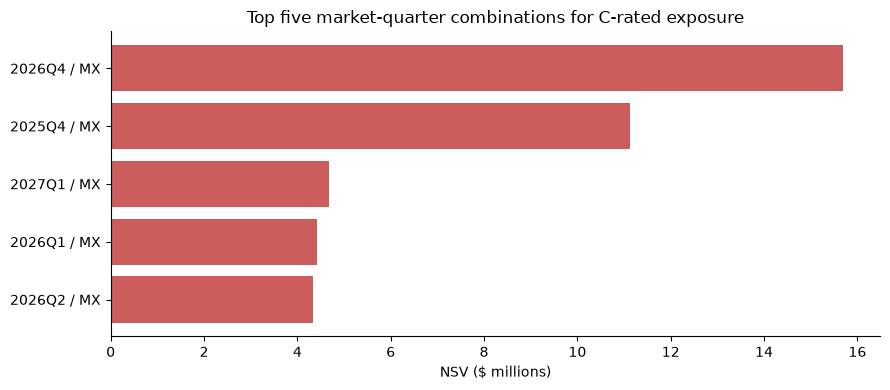

In [46]:
top_c = (
    quarterly_exposure[
        quarterly_exposure["credit_rating"] == "C"
    ]
    .nlargest(5, "nsv")
    .copy()
)

top_c["nsv_million"] = top_c["nsv"] / 1_000_000

print("Highest C-rated exposure:")
print(
    top_c[["planning_quarter", "market_destination", "nsv_million"]]
    .round(1)
    .to_string(index=False)
)

labels = top_c["planning_quarter"] + " / " + top_c["market_destination"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(labels, top_c["nsv_million"], color="indianred")
ax.invert_yaxis()
ax.set(
    title="Top five market-quarter combinations for C-rated exposure",
    xlabel="NSV ($ millions)"
)
plt.tight_layout()
plt.show()

Mexico has the five largest market-quarter combinations for C-rated order value. The highest is 2026Q4 at approximately $15.7M, followed by 2025Q4 at $11.1M. These results identify useful cases for testing customer holds; they do not mean that all C-rated orders should automatically be held.

| Finding | Project requirement | Planning implication |
|---|---|---|
| C-rated customers have recorded orders in V5 | Customer-hold scenario | Use a selected C-rated customer to demonstrate which requests and order value are affected. |
| Removing customer demand reduces quantities | MOQ/MPQ checks | Recalculate the remaining quantities after a hold and show any shortfall. |